# UrbanHub · Partie 3 : Pollution de l'air (OpenAQ)

**Développeur 3** · Sources : `clean/openaq/measurements` (une ligne par capteur et par heure) et
`curated/openaq/pollution_city_hourly` (une ligne par ville et par heure), produites par `pipelines/iot_openaq/`.
Stations officielles uniquement (réseau EEA), Paris, Lyon et Lille, de janvier 2024 à octobre 2026.

| # | Question métier | Indicateur |
|---|---|---|
| 1 | Zones les plus polluées | concentration moyenne par station, rapportée au seuil annuel de l'OMS |
| 2 | Variation journalière | concentration moyenne selon l'heure de la journée (heure de Paris), semaine / week-end |
| 3 | Polluants dominants | polluant le plus élevé par rapport à son seuil journalier OMS, jour par jour |
| 4 | Épisodes anormaux | z-score des moyennes journalières + IsolationForest sur les heures |

> **Seuils de référence** : lignes directrices de l'OMS 2021 (µg/m³).
> Annuel : PM2.5 = 5, PM10 = 15, NO₂ = 10. Journalier (24 h) : PM2.5 = 15, PM10 = 45, NO₂ = 25, CO = 4 000.
> O₃ : 100 sur 8 h (on l'applique ici au maximum journalier des moyennes glissantes sur 8 h).

In [1]:
import gzip, json, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "common").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from common import config
from common.schemas import POLLUTANTS

sns.set_theme(style="whitegrid", font="DejaVu Sans")   # police qui affiche NO₂ et O₃
FIG = ROOT / "docs" / "resultats" / "figures" / "pollution"
FIG.mkdir(parents=True, exist_ok=True)
TZ = "Europe/Paris"
CITY_COLORS = {"paris": "#1f77b4", "lyon": "#d62728", "lille": "#2ca02c"}
LABELS = {"pm25": "PM2.5", "pm10": "PM10", "no2": "NO₂", "o3": "O₃", "co": "CO"}
OMS_ANNUEL = {"pm25": 5, "pm10": 15, "no2": 10}
OMS_JOUR = {"pm25": 15, "pm10": 45, "no2": 25, "o3": 100, "co": 4000}

def lire(couche, chemin):
    return pd.read_parquet(config.lake_uri(couche, chemin))

def heure_locale(df):
    df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.tz_localize("UTC")
    df["heure_locale"] = df["timestamp"].dt.tz_convert(TZ)
    return df

mes = heure_locale(lire("clean", "openaq/measurements"))
city = heure_locale(lire("curated", "openaq/pollution_city_hourly"))

# Nom des stations : dernier fichier de stations téléchargé pour chaque ville (couche raw)
noms = {}
for f in sorted((config.LOCAL_LAKE / "raw" / "openaq" / "locations").rglob("*.json.gz")):
    for loc in json.loads(gzip.decompress(f.read_bytes()))["results"]:
        for s in loc["sensors"]:
            noms[str(s["id"])] = loc["name"]
mes["station"] = mes["sensor_id"].map(noms)

periode = f"{city.heure_locale.min():%d/%m/%Y} → {city.heure_locale.max():%d/%m/%Y}"
print("Période analysée :", periode)
print(f"{mes.sensor_id.nunique()} capteurs · {mes.station.nunique()} stations · {len(mes):,} mesures horaires")
heures_possibles = (city.timestamp.max() - city.timestamp.min()) / pd.Timedelta(hours=1) + 1
city.groupby("city").agg(heures=("timestamp", "nunique"), capteurs_moyens=("nb_sensors", "mean")).assign(
    couverture=lambda d: (d.heures / heures_possibles).map("{:.0%}".format)
).round(1)

Période analysée : 01/01/2024 → 01/11/2026
129 capteurs · 51 stations · 1,840,837 mesures horaires


,heures,capteurs_moyens,couverture
city,,,
lille,22207,12.8,89%
lyon,18849,21.9,76%
paris,19685,56.6,79%


## Q1 · Quelles sont les zones les plus polluées ?

On calcule la concentration moyenne de chaque station sur toute la période, puis on la divise par le seuil annuel
de l'OMS : **1 = au niveau du seuil, 2 = deux fois le seuil**. Les stations de trafic (périphérique, autoroute)
ressortent en tête pour le NO₂, qui vient surtout des pots d'échappement.

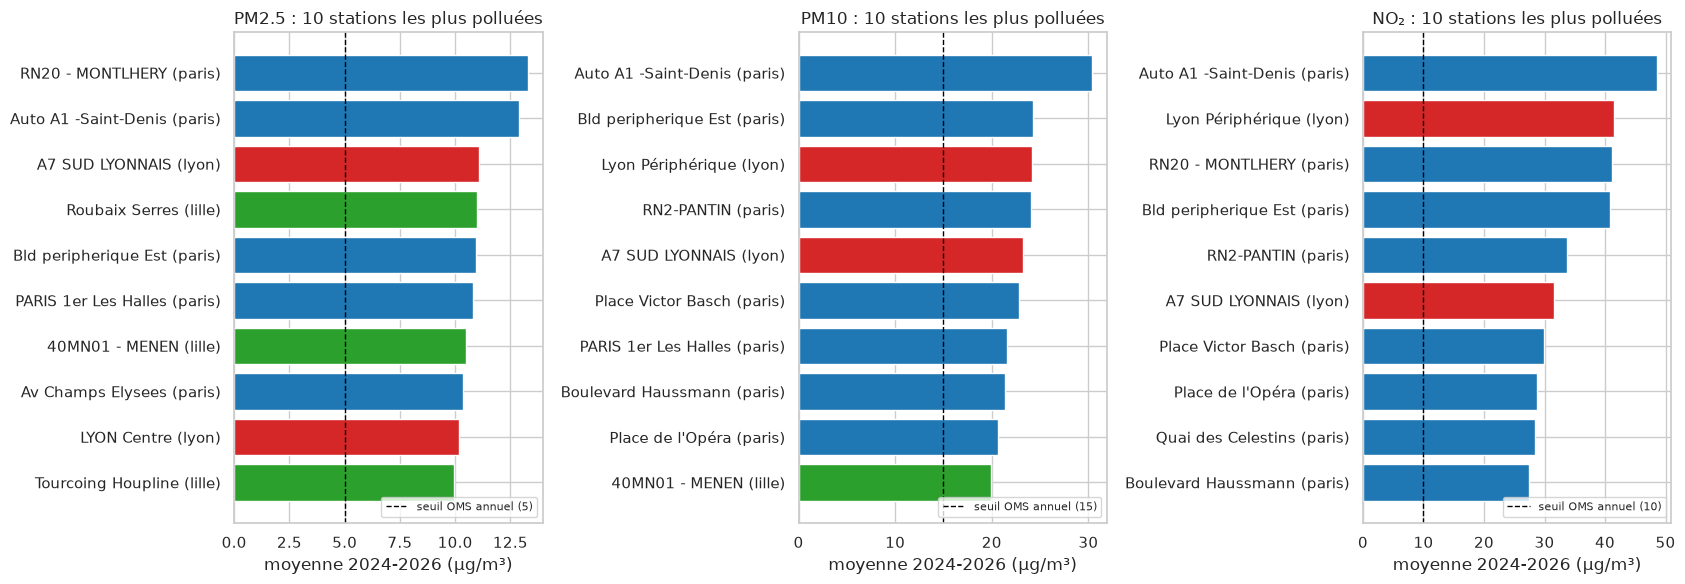

Moyenne des stations par ville, en multiple du seuil OMS annuel :


pollutant,no2,pm10,pm25
city,,,
lille,1.3,1.1,1.9
lyon,2.0,1.2,1.9
paris,2.3,1.3,2.1


In [2]:
st = (mes.dropna(subset=["value"]).groupby(["city", "station", "pollutant"])
      .agg(moyenne=("value", "mean"), heures=("value", "size"), lat=("latitude", "first"), lon=("longitude", "first"))
      .reset_index())
st = st[st.heures >= 24 * 90]                       # au moins 3 mois de mesures pour une moyenne fiable
st = st[st.pollutant.isin(OMS_ANNUEL)].copy()
st["x_seuil_oms"] = st.moyenne / st.pollutant.map(OMS_ANNUEL)

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, p in zip(axes, OMS_ANNUEL):
    top = st[st.pollutant == p].nlargest(10, "moyenne").sort_values("moyenne")
    ax.barh(top.station + " (" + top.city + ")", top.moyenne, color=top.city.map(CITY_COLORS))
    ax.axvline(OMS_ANNUEL[p], color="black", ls="--", lw=1, label=f"seuil OMS annuel ({OMS_ANNUEL[p]})")
    ax.set_title(f"{LABELS[p]} : 10 stations les plus polluées")
    ax.set_xlabel("moyenne 2024-2026 (µg/m³)")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "q1_stations_polluees.png", dpi=120)
plt.show()

print("Moyenne des stations par ville, en multiple du seuil OMS annuel :")
st.pivot_table(index="city", columns="pollutant", values="x_seuil_oms", aggfunc="mean").round(1)

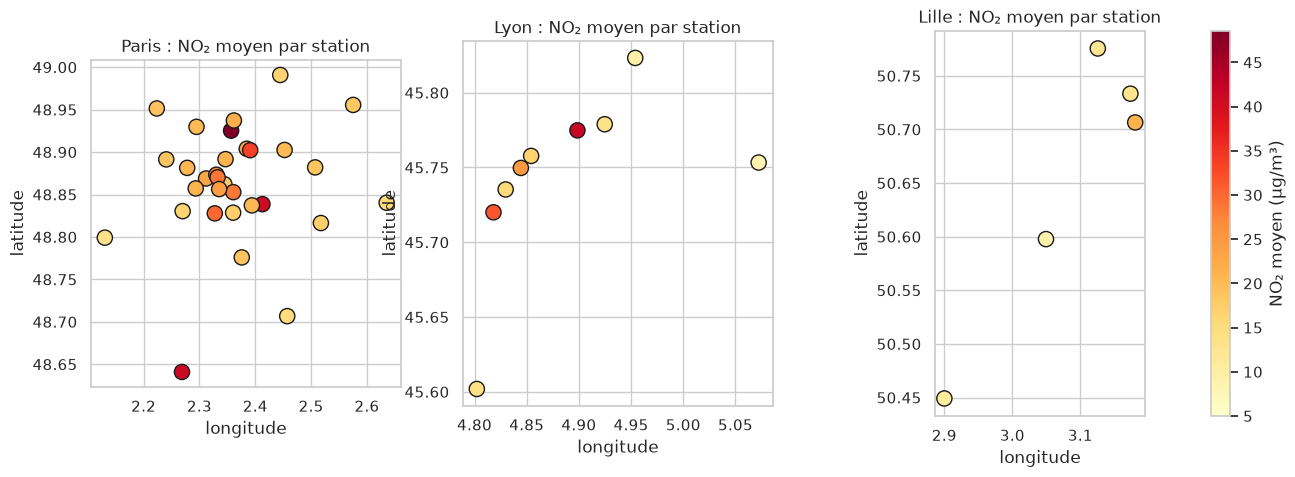

In [3]:
# Carte : position des stations, couleur = NO₂ moyen
no2 = st[st.pollutant == "no2"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, c in zip(axes, ["paris", "lyon", "lille"]):
    d = no2[no2.city == c]
    sc = ax.scatter(d.lon, d.lat, c=d.moyenne, cmap="YlOrRd", s=120, edgecolor="k", vmin=5, vmax=no2.moyenne.max())
    ax.set_title(f"{c.capitalize()} : NO₂ moyen par station")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.set_aspect(1 / np.cos(np.radians(d.lat.mean())))
fig.colorbar(sc, ax=axes, label="NO₂ moyen (µg/m³)")
plt.savefig(FIG / "q1_carte_no2.png", dpi=120, bbox_inches="tight")
plt.show()

## Q2 · Comment la pollution varie-t-elle au cours de la journée ?

Profil moyen par heure (heure de Paris). En semaine, le NO₂ suit le trafic : un pic le matin et un autre en fin de
journée. L'ozone fait l'inverse : il se forme sous l'effet du soleil et culmine l'après-midi.

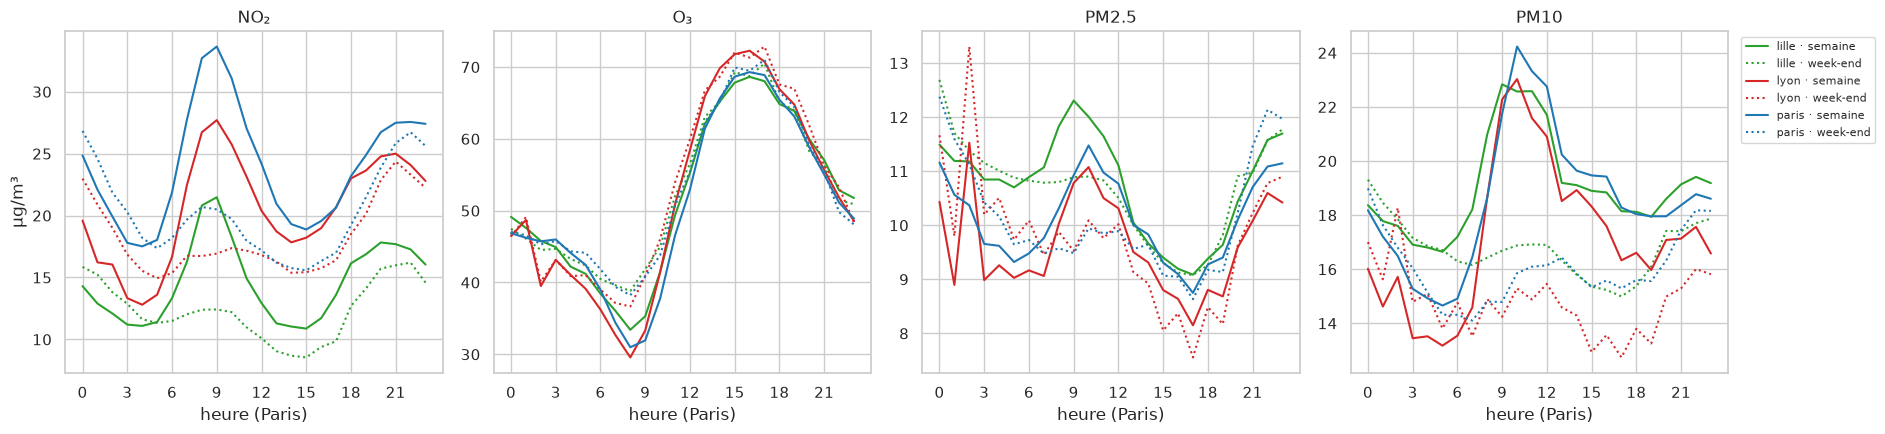

heure du pic (semaine),CO,NO₂,O₃,PM10,PM2.5
city,,,,,
lille,20,9,16,9,9
lyon,8,9,16,10,2
paris,10,9,16,10,10


In [4]:
city["heure"] = city.heure_locale.dt.hour
city["jour"] = np.where(city.heure_locale.dt.day_of_week >= 5, "week-end", "semaine")
prof = city.melt(id_vars=["city", "heure", "jour"], value_vars=list(POLLUTANTS), var_name="pollutant").dropna()
prof = prof.groupby(["pollutant", "city", "jour", "heure"]).value.mean().reset_index()

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5), sharex=True)
for ax, p in zip(axes, ["no2", "o3", "pm25", "pm10"]):
    for (c, j), d in prof[prof.pollutant == p].groupby(["city", "jour"]):
        ax.plot(d.heure, d.value, color=CITY_COLORS[c], ls="-" if j == "semaine" else ":",
                label=f"{c} · {j}")
    ax.set_title(LABELS[p]); ax.set_xlabel("heure (Paris)"); ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("µg/m³")
axes[-1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG / "q2_profil_journalier.png", dpi=120, bbox_inches="tight")
plt.show()

pics = prof[prof.jour == "semaine"].loc[lambda d: d.groupby(["pollutant", "city"]).value.idxmax()]
pics.pivot(index="city", columns="pollutant", values="heure").rename(columns=LABELS).rename_axis(
    "heure du pic (semaine)", axis=1)

## Q3 · Quels polluants dominent ?

Pour chaque ville et chaque jour, on divise la moyenne journalière de chaque polluant par son seuil journalier OMS.
Le **polluant dominant** est celui qui a le rapport le plus élevé ce jour-là : c'est lui qui pèse le plus sur la
qualité de l'air. Un rapport supérieur à 1 signifie que le seuil OMS est dépassé.

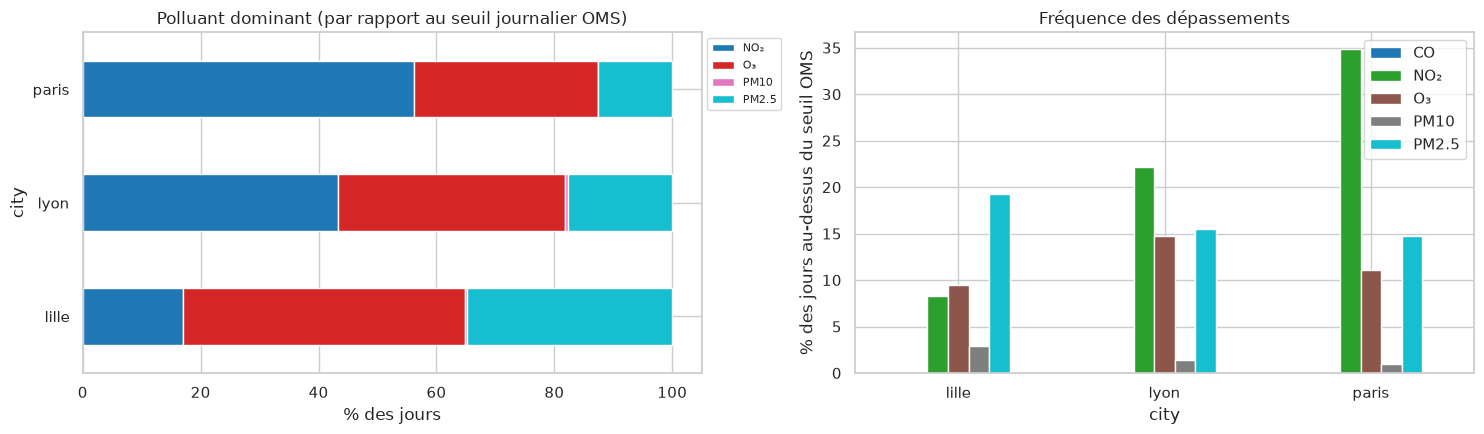

dominant,NO₂,O₃,PM10,PM2.5
city,,,,
lille,17.0,48.0,0.0,35.0
lyon,43.0,39.0,0.0,18.0
paris,56.0,31.0,0.0,13.0


In [5]:
parts = []
for c, d in city.groupby("city"):
    d = d.set_index("heure_locale").sort_index()
    j = d[["pm25", "pm10", "no2", "co"]].resample("D").mean()
    # O₃ : maximum journalier des moyennes glissantes sur 8 h
    j["o3"] = d["o3"].rolling("8h", min_periods=6).mean().resample("D").max()
    parts.append(j.assign(city=c))
jour = pd.concat(parts).rename_axis("jour").reset_index().set_index(["city", "jour"])
ratio = (jour / pd.Series(OMS_JOUR)).dropna(how="all")

dominant = ratio.idxmax(axis=1).rename("dominant").reset_index()
part = (dominant.groupby("city").dominant.value_counts(normalize=True).unstack().fillna(0) * 100)
part = part.rename(columns=LABELS)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
part.plot.barh(stacked=True, ax=axes[0], colormap="tab10")
axes[0].set_xlabel("% des jours"); axes[0].set_title("Polluant dominant (par rapport au seuil journalier OMS)")
axes[0].legend(fontsize=8, bbox_to_anchor=(1.0, 1), loc="upper left")
depass = (ratio > 1).groupby("city").mean().mul(100).rename(columns=LABELS)
depass.plot.bar(ax=axes[1], colormap="tab10", rot=0)
axes[1].set_ylabel("% des jours au-dessus du seuil OMS"); axes[1].set_title("Fréquence des dépassements")
plt.tight_layout()
plt.savefig(FIG / "q3_polluants_dominants.png", dpi=120, bbox_inches="tight")
plt.show()
part.round(0)

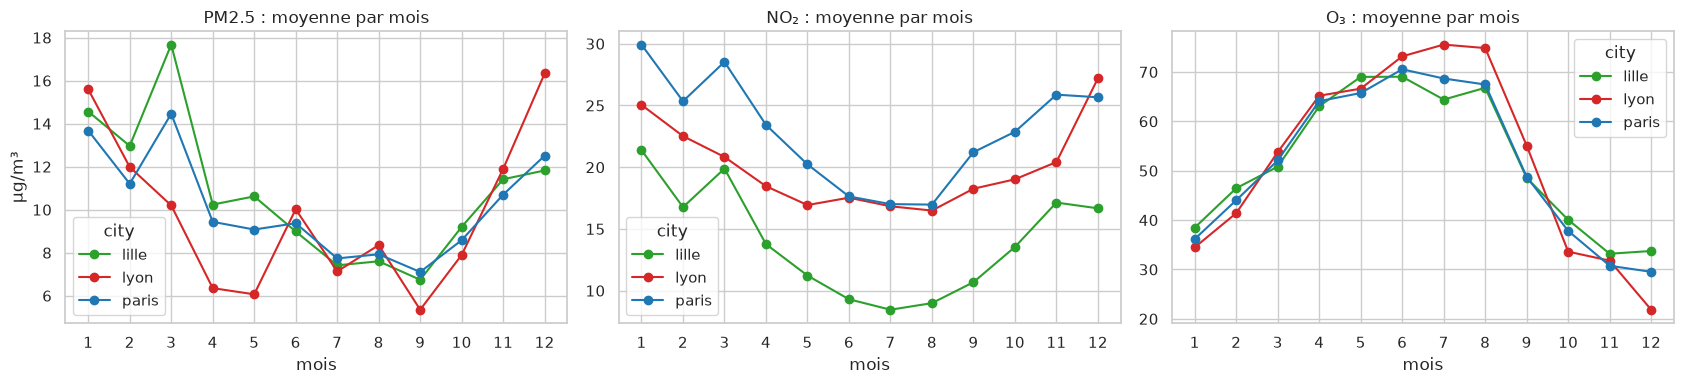

In [6]:
# Saisonnalité : moyenne mensuelle de chaque polluant (toutes villes)
mois = city.assign(mois=city.heure_locale.dt.month).groupby(["mois", "city"])[["pm25", "no2", "o3"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharex=True)
for ax, p in zip(axes, ["pm25", "no2", "o3"]):
    mois[p].unstack().plot(ax=ax, color=CITY_COLORS, marker="o")
    ax.set_title(f"{LABELS[p]} : moyenne par mois"); ax.set_xlabel("mois"); ax.set_xticks(range(1, 13))
axes[0].set_ylabel("µg/m³")
plt.tight_layout()
plt.savefig(FIG / "q3_saisonnalite.png", dpi=120)
plt.show()

## Q4 · Peut-on détecter des épisodes anormaux ?

Deux méthodes complémentaires :

1. **z-score** sur les moyennes journalières : on compare chaque jour à la moyenne et à l'écart-type des 30 jours
   précédents. Un z-score supérieur à 3 signifie un jour très au-dessus de l'habitude récente.
2. **IsolationForest** (scikit-learn) sur les heures : le modèle regarde tous les polluants en même temps et isole
   les heures dont la combinaison est inhabituelle. On garde les 0,5 % d'heures les plus atypiques par ville.

223 jours-polluants anormaux (z > 3) :
pollutant  no2  pm10  pm25
city                      
lille       23    28    38
lyon         9    26    33
paris       21    18    27


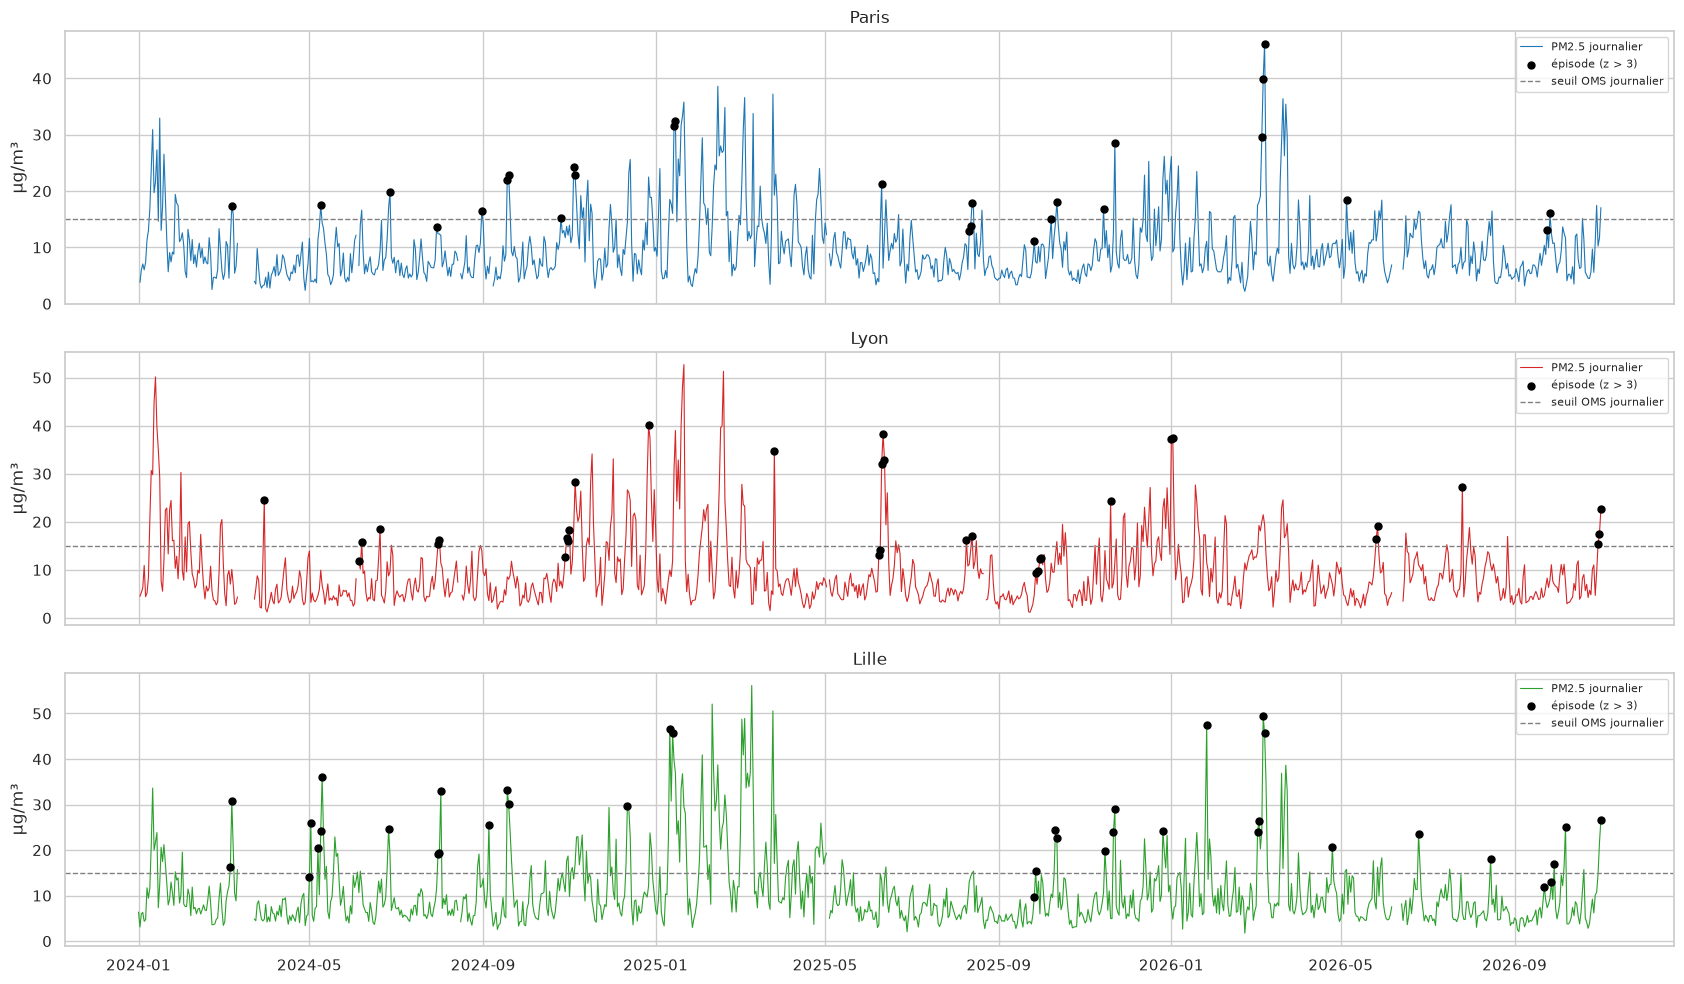

Les 10 épisodes les plus marqués :


,jour,city,pollutant,valeur,z
3630,2025-06-10,lyon,pm25,32.1,9.8
1717,2025-11-14,paris,pm10,42.7,9.7
6332,2024-05-02,lille,pm25,25.9,8.1
4665,2025-06-10,lyon,pm10,40.6,7.5
6276,2024-03-07,lille,pm25,30.8,7.3
6424,2024-08-02,lille,pm25,33.0,6.8
1295,2024-09-18,paris,pm10,51.2,6.6
690,2025-11-22,paris,pm25,28.5,6.6
4041,2026-07-26,lyon,pm25,27.3,6.3
5108,2026-08-27,lyon,pm10,57.9,6.2


In [7]:
Z_SEUIL = 3
z = []
for c in ["paris", "lyon", "lille"]:
    for p in ["pm25", "pm10", "no2"]:
        s = jour.loc[c, p]
        base = s.shift(1).rolling(30, min_periods=20)   # les 30 jours précédents
        z.append(pd.DataFrame({"city": c, "pollutant": p, "valeur": s, "z": (s - base.mean()) / base.std()}))
z = pd.concat(z).reset_index()
episodes = z[z.z > Z_SEUIL]
print(f"{len(episodes)} jours-polluants anormaux (z > {Z_SEUIL}) :")
print(episodes.groupby(["city", "pollutant"]).size().unstack(fill_value=0))

fig, axes = plt.subplots(3, 1, figsize=(17, 10), sharex=True)
for ax, c in zip(axes, ["paris", "lyon", "lille"]):
    s = jour.loc[c, "pm25"]
    ax.plot(s.index, s, color=CITY_COLORS[c], lw=0.8, label="PM2.5 journalier")
    e = episodes[(episodes.city == c) & (episodes.pollutant == "pm25")]
    ax.scatter(e.jour, e.valeur, color="black", zorder=3, s=25, label=f"épisode (z > {Z_SEUIL})")
    ax.axhline(OMS_JOUR["pm25"], color="grey", ls="--", lw=1, label="seuil OMS journalier")
    ax.set_title(c.capitalize()); ax.set_ylabel("µg/m³"); ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "q4_episodes_pm25.png", dpi=120)
plt.show()

print("Les 10 épisodes les plus marqués :")
episodes.nlargest(10, "z").assign(jour=lambda d: d.jour.dt.date)[
    ["jour", "city", "pollutant", "valeur", "z"]].round(1)

Heures atypiques (IsolationForest) : 283 sur 56,226

Profil moyen : heures normales vs atypiques (µg/m³)


pm25  pm10   no2    o3
city  anomalie                        
lille False     10.6  18.0  14.0  52.2
      True      67.7  89.3  45.4  20.8
lyon  False      9.5  16.3  19.9  52.4
      True      51.3  74.5  38.1  34.3
paris False     10.0  17.7  22.9  51.6
      True      47.3  64.0  56.2  14.3

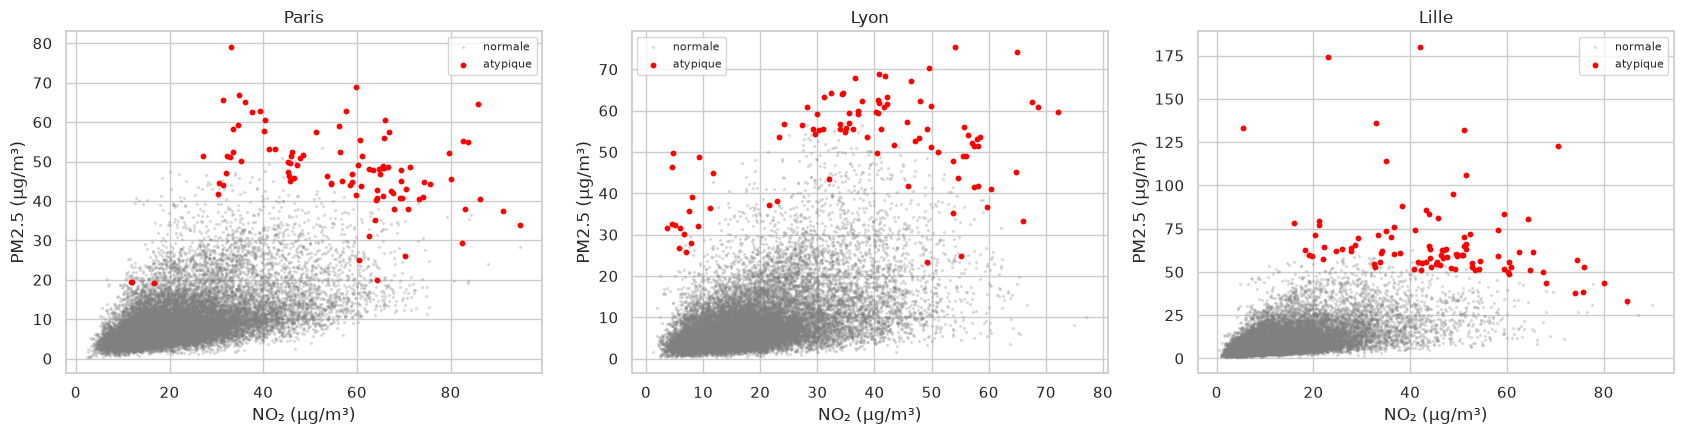

,city,jour,heures_atypiques
0,lille,2025-03-05,16
1,lille,2025-03-10,15
2,paris,2025-03-05,15
3,paris,2024-01-16,11
4,lyon,2025-01-21,10
5,lyon,2025-01-20,10
6,paris,2026-03-08,10
7,lyon,2024-12-27,9
8,lyon,2025-02-18,8
9,paris,2026-03-07,8


In [8]:
anom = []
for c, d in city.groupby("city"):
    X = d.set_index("heure_locale")[["pm25", "pm10", "no2", "o3"]].dropna()
    model = IsolationForest(contamination=0.005, random_state=42).fit(X)
    X = X.assign(anomalie=model.predict(X) == -1, city=c)
    anom.append(X)
anom = pd.concat(anom)
print(f"Heures atypiques (IsolationForest) : {anom.anomalie.sum():,} sur {len(anom):,}")
print("\nProfil moyen : heures normales vs atypiques (µg/m³)")
display(anom.groupby(["city", "anomalie"])[["pm25", "pm10", "no2", "o3"]].mean().round(1))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, c in zip(axes, ["paris", "lyon", "lille"]):
    d = anom[anom.city == c]
    ax.scatter(d.no2, d.pm25, s=2, alpha=0.2, color="grey", label="normale")
    a = d[d.anomalie]
    ax.scatter(a.no2, a.pm25, s=10, color="red", label="atypique")
    ax.set_title(c.capitalize()); ax.set_xlabel("NO₂ (µg/m³)"); ax.set_ylabel("PM2.5 (µg/m³)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "q4_isolation_forest.png", dpi=120)
plt.show()

# Jours qui concentrent le plus d'heures atypiques
(anom[anom.anomalie].assign(jour=lambda d: d.index.date).groupby(["city", "jour"]).size()
 .rename("heures_atypiques").sort_values(ascending=False).head(10).reset_index())

## Limites

- **Couverture incomplète** : selon la ville, 76 % à 89 % des heures ont au moins une mesure. Les trous viennent
  d'OpenAQ, pas de la collecte.
- **Le CO** n'est mesuré que par une station par ville ; à Lille, il s'arrête en janvier 2025.
- La position des stations n'est pas représentative de toute la ville : plusieurs sont des stations de trafic, qui
  surestiment l'exposition moyenne des habitants.
- Le mois en cours n'est pas inclus tant que le collecteur `live` ne tourne pas.
- Relancer ce notebook après `clean` et `curate` pour mettre les résultats à jour.